# Importando librerias

In [1]:
import pandas as pd
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, roc_auc_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder 
from xgboost import XGBClassifier
from joblib import dump, load

In [4]:
df = pd.read_csv("./data/FraudTrainAnalyzed.csv")
warnings.simplefilter("ignore")
df.pop("Unnamed: 0")
df.head()

,trans_num,trans_date,cc_num,merchant,type_purcharse,amount,gender,city,state,city_pop,...,merch_long,fraud,trans_year,trans_month,age,age_groups,name,cat_amount,unique_person,time
0,0b242abb623afc578575680df30655b9,2019-01-01,2703186189652095,"Rippin, Kub and Mann",misc_net,4.97,F,Moravian Falls,NC,3495,...,-82.048315,0,2019,january,32,Adult,Jennifer_Banks,1,Jennifer_Banks / 32,2019-01
1,1f76529f8574734946361c461b024d99,2019-01-01,630423337322,"Heller, Gutmann and Zieme",grocery_pos,107.23,F,Orient,WA,149,...,-118.186462,0,2019,january,42,Adult,Stephanie_Gill,1,Stephanie_Gill / 42,2019-01
2,a1a22d70485983eac12b5b88dad1cf95,2019-01-01,38859492057661,Lind-Buckridge,entertainment,220.11,M,Malad City,ID,4154,...,-112.154481,0,2019,january,58,Adult,Edward_Sanchez,1,Edward_Sanchez / 58,2019-01
3,6b849c168bdad6f867558c3793159a81,2019-01-01,3534093764340240,"Kutch, Hermiston and Farrell",gas_transport,45.00,M,Boulder,MT,1939,...,-112.561071,0,2019,january,53,Adult,Jeremy_White,1,Jeremy_White / 53,2019-01
4,a41d7549acf90789359a9aa5346dcb46,2019-01-01,375534208663984,Keeling-Crist,misc_pos,41.96,M,Doe Hill,VA,99,...,-78.632459,0,2019,january,34,Adult,Tyler_Garcia,1,Tyler_Garcia / 34,2019-01


In [ ]:
df.info()

# Preprocesamiento

In [5]:
data = df[["merchant","type_purcharse","amount","gender","state","job","trans_year","trans_month", "age_groups", "fraud"]]
#data.set_index("trans_num", inplace=True)
data.head()

,merchant,type_purcharse,amount,gender,state,job,trans_year,trans_month,age_groups,fraud
0,"Rippin, Kub and Mann",misc_net,4.97,F,NC,health and medicine,2019,january,Adult,0
1,"Heller, Gutmann and Zieme",grocery_pos,107.23,F,WA,education and academia,2019,january,Adult,0
2,Lind-Buckridge,entertainment,220.11,M,ID,environmental science and conservation,2019,january,Adult,0
3,"Kutch, Hermiston and Farrell",gas_transport,45.00,M,MT,legal and law,2019,january,Adult,0
4,Keeling-Crist,misc_pos,41.96,M,VA,psychology and social work,2019,january,Adult,0


In [6]:
clientes = df[["name", "age", "cc_num", "trans_date", "city", "city_pop", "merch_lat", "merch_long", "trans_num"]]
#clientes.set_index("trans_num", inplace=True)
clientes.head()

,name,age,cc_num,trans_date,city,city_pop,merch_lat,merch_long,trans_num
0,Jennifer_Banks,32,2703186189652095,2019-01-01,Moravian Falls,3495,36.011293,-82.048315,0b242abb623afc578575680df30655b9
1,Stephanie_Gill,42,630423337322,2019-01-01,Orient,149,49.159047,-118.186462,1f76529f8574734946361c461b024d99
2,Edward_Sanchez,58,38859492057661,2019-01-01,Malad City,4154,43.150704,-112.154481,a1a22d70485983eac12b5b88dad1cf95
3,Jeremy_White,53,3534093764340240,2019-01-01,Boulder,1939,47.034331,-112.561071,6b849c168bdad6f867558c3793159a81
4,Tyler_Garcia,34,375534208663984,2019-01-01,Doe Hill,99,38.674999,-78.632459,a41d7549acf90789359a9aa5346dcb46


In [7]:
age_cat = ["Minor", "Adult", "Elder"]
month_cat = list(data["trans_month"].unique())

cod_or_age = OrdinalEncoder(categories=[age_cat])
data["age_groups"] = cod_or_age.fit_transform(data[["age_groups"]])

cod_or_month = OrdinalEncoder(categories=[month_cat])
data["trans_month"] = cod_or_month.fit_transform(data[["trans_month"]])

data.head()

,merchant,type_purcharse,amount,gender,state,job,trans_year,trans_month,age_groups,fraud
0,"Rippin, Kub and Mann",misc_net,4.97,F,NC,health and medicine,2019,0.0,1.0,0
1,"Heller, Gutmann and Zieme",grocery_pos,107.23,F,WA,education and academia,2019,0.0,1.0,0
2,Lind-Buckridge,entertainment,220.11,M,ID,environmental science and conservation,2019,0.0,1.0,0
3,"Kutch, Hermiston and Farrell",gas_transport,45.00,M,MT,legal and law,2019,0.0,1.0,0
4,Keeling-Crist,misc_pos,41.96,M,VA,psychology and social work,2019,0.0,1.0,0


In [8]:
cols = ["type_purcharse","gender","job"]

for col in cols:
    encoder = OneHotEncoder()
    encoder_col = encoder.fit_transform(data[[col]])
    df_col = pd.DataFrame(encoder_col.toarray(), columns=encoder.categories_)
    data = pd.concat([data,df_col], axis=1)

data.drop(labels=["type_purcharse","gender","job"], axis=1, inplace=True)
data.head()

,merchant,amount,state,trans_year,trans_month,age_groups,fraud,"(entertainment,)","(food_dining,)","(gas_transport,)",...,"(logistics and transportation,)","(marketing, advertising, and sales,)","(media and journalism,)","(others,)","(psychology and social work,)","(retail and commerce,)","(science and research,)","(sports and physical health,)","(surveying and planning,)","(tourism and hospitality,)"
0,"Rippin, Kub and Mann",4.97,NC,2019,0.0,1.0,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,"Heller, Gutmann and Zieme",107.23,WA,2019,0.0,1.0,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Lind-Buckridge,220.11,ID,2019,0.0,1.0,0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,"Kutch, Hermiston and Farrell",45.00,MT,2019,0.0,1.0,0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Keeling-Crist,41.96,VA,2019,0.0,1.0,0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [9]:
data.drop(labels=["merchant","state"],axis=1,inplace=True)

In [10]:
data.columns = [str(col[0]) if isinstance(col, tuple) else col for col in data.columns] 

In [11]:
Y = data["fraud"]
data.drop(labels=["fraud"], axis=1, inplace=True)
X = data
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.1, random_state=42)

# Bosque Aleatorio 

## Creando modelo

In [11]:
# Creación del modelo base
bosque = RandomForestClassifier(oob_score=True, random_state=123)

In [ ]:
# Entrenando...
bosque.fit(x_train, y_train)

In [12]:
# Puntaje de validación
bosque.oob_score_

AttributeError: 'RandomForestClassifier' object has no attribute 'oob_score_'

In [ ]:
# Matriz de probabilidades de que una transaccion sea fraudulenta o no
oob_probs = bosque.oob_decision_function_
oob_preds = np.argmax(oob_probs, axis=1)

In [ ]:
oob_preds

In [4]:
# Recojiendo predicciones del set de entrenamiento
y_pred = bosque.predict(x_train)

NameError: name 'x_train' is not defined

## Resultados set entrenamiento

In [13]:
y_pred = bosque.predict(x_train)

In [14]:
recall = recall_score(y_train, y_pred)
f1 = f1_score(y_train, y_pred)
precision = precision_score(y_train, y_pred)
accuracy = accuracy_score(y_train, y_pred)
roc = roc_auc_score(y_train, y_pred)

print("Metricas para conjunto de validación y entrenamiento")
print("puntuación: ", accuracy )
print("AUC: ", roc)
print("recall: ", recall)
print("f1: ", f1)
print("precision: ", precision)

Metricas para conjunto de validación y entrenamiento
puntuación:  0.9980360014978488
AUC:  0.855412622897764
recall:  0.7111243130848062
f1:  0.8068756319514662
precision:  0.9324245374878286


In [15]:
# Matriz de probabilidades de que una transacción sea fraude para set de prueba
y_probs = bosque.predict_proba(x_test)[:,1]

In [ ]:
y_probs

## Resultados set prueba

In [16]:
# Evaluando para set de prueba
y_pred = bosque.predict(x_test)

recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
roc = roc_auc_score(y_test, y_probs)

print("Metricas para conjunto de prueba")
print("puntuación: ", accuracy)
print("recall: ", recall)
print("AUC: ", roc)
print("f1: ", f1)
print("precision: ", precision)

Metricas para conjunto de prueba
puntuación:  0.997192830922047
recall:  0.6235446313065977
AUC:  0.9929326030137651
f1:  0.7259036144578314
precision:  0.8684684684684685


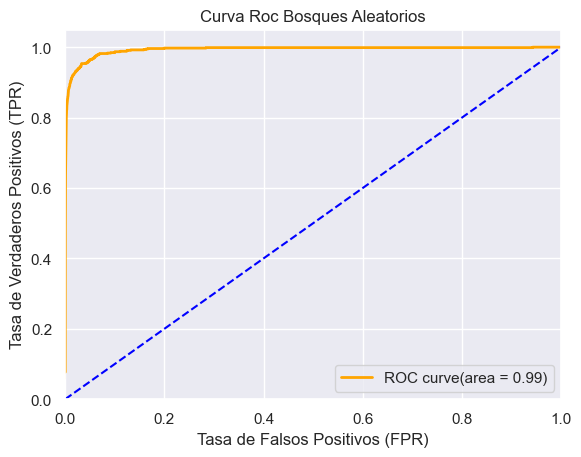

In [17]:
tfp, tvp, thr = roc_curve(y_test, y_probs)
roc_auc = auc(tfp,tvp)

sns.set_theme(style="darkgrid")

sns.lineplot(x=tfp, y=tvp, color="orange", label=f"ROC curve(area = {roc_auc:.2f})", lw=2, linestyle="-")
sns.lineplot(x=[1,0], y=[1,0], color="blue", linestyle="--")
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva Roc Bosques Aleatorios")
plt.show()

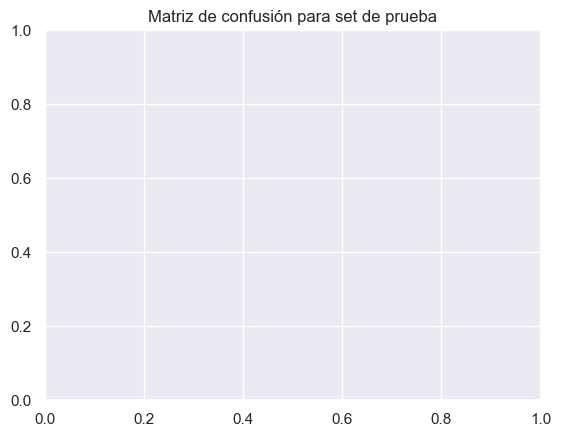

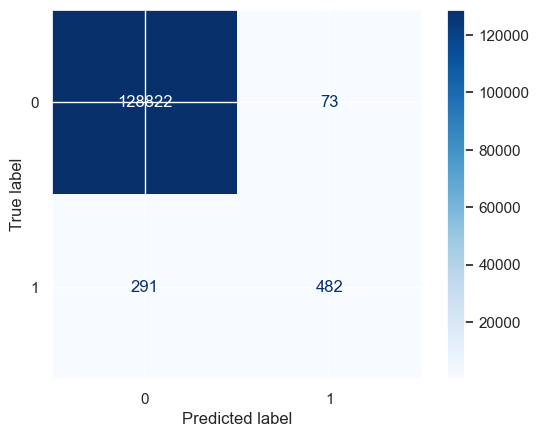

In [18]:
cm = confusion_matrix(y_test, y_pred)
disp= ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=bosque.classes_)
plt.title("Matriz de confusión para set de prueba")
disp.plot(cmap="Blues")

In [19]:
# Validacion cruzada
scores = cross_val_score(bosque, X, Y, cv=5)
print(scores)

KeyboardInterrupt: 

## Efecto de hiperparametros

In [7]:
# Creando modelo
bosque_h = RandomForestClassifier(oob_score=True, random_state=123)

In [8]:
# Definiendo red de hiperparametros
parametros = {"n_estimators": np.arange(10,301,10),
              "max_depth": [None] + list(np.arange(5,51,5)),
              "max_features": ["log2","sqrt","auto"],
              "bootstrap": [True, False],
              "min_samples_split": np.arange(1,11,1),
              "min_samples_leaf": np.arange(1,6,1)}

In [9]:
# Usando Random Search para buscar los mejores hiperparametros
seleccion_aleatoria = RandomizedSearchCV(estimator=bosque_h, param_distributions=parametros, scoring="recall")
seleccion_aleatoria.fit(x_train,y_train)

C:\Users\lufel\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\lufel\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\lufel\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\lufel\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\lufel\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probab

RandomizedSearchCV(estimator=RandomForestClassifier(oob_score=True,
                                                    random_state=123),
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [None, 5, 10, 15, 20, 25,
                                                      30, 35, 40, 45, 50],
                                        'max_features': ['log2', 'sqrt',
                                                         'auto'],
                                        'min_samples_leaf': array([1, 2, 3, 4, 5]),
                                        'min_samples_split': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10]),
                                        'n_estimators': array([ 10,  20,  30,  40,  50,  60,  70,  80,  90, 100, 110, 120, 130,
       140, 150, 160, 170, 180, 190, 200, 210, 220, 230, 240, 250, 260,
       270, 280, 290, 300])},
                   scoring='recall')

In [10]:
seleccion_aleatoria.best_params_

{'n_estimators': 30,
 'min_samples_split': 2,
 'min_samples_leaf': 2,
 'max_features': 'sqrt',
 'max_depth': None,
 'bootstrap': True}

In [57]:
# Modelo con los mejores parametros
bosque_h = RandomForestClassifier(n_estimators=130, min_samples_split=6, min_samples_leaf=1, bootstrap=True, max_features="sqrt", max_depth=20, oob_score=True, random_state=123)

In [12]:
bosque_h.fit(x_train, y_train)

C:\Users\lufel\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


RandomForestClassifier(min_samples_leaf=2, n_estimators=30, oob_score=True,
                       random_state=123)

In [13]:
bosque_h.oob_score_

0.9972159550028405

In [14]:
y_pred = bosque_h.predict(x_train)

In [15]:
recall = recall_score(y_train, y_pred)
f1 = f1_score(y_train, y_pred)
precision = precision_score(y_train, y_pred)
accuracy = accuracy_score(y_train, y_pred)
roc = roc_auc_score(y_train, y_pred)

print("Metricas para conjunto de validación y entrenamiento")
print("puntuación: ", accuracy )
print("AUC: ", roc)
print("recall: ", recall)
print("f1: ", f1)
print("precision: ", precision)

Metricas para conjunto de validación y entrenamiento
puntuación:  0.9983110641152967
AUC:  0.8800625685136741
recall:  0.7604336848358829
f1:  0.8385881582180001
precision:  0.9346476816356335


In [16]:
y_probs = bosque_h.predict_proba(x_test)[:,1]

In [ ]:
y_probs

In [17]:
y_pred = bosque_h.predict(x_test)

recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
roc = roc_auc_score(y_test, y_probs)

print("Metricas para conjunto de prueba")
print("puntuación: ", accuracy)
print("recall: ", recall)
print("AUC: ", roc)
print("f1: ", f1)
print("precision: ", precision)

Metricas para conjunto de prueba
puntuación:  0.9971619829102014
recall:  0.6364812419146184
AUC:  0.9741089990363405
f1:  0.727810650887574
precision:  0.8497409326424871


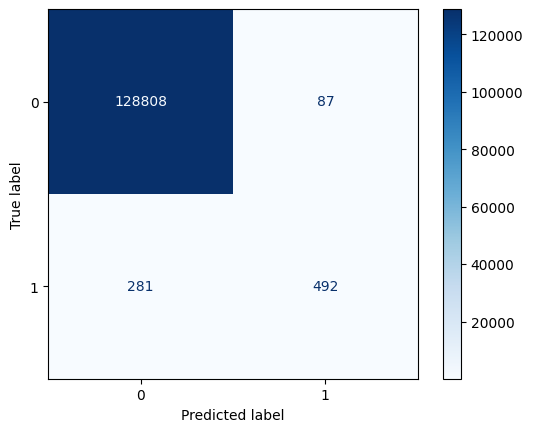

In [19]:
cm = confusion_matrix(y_test, y_pred)
disp= ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=bosque_h.classes_)
disp.plot(cmap="Blues")

# Gradient boosting

In [6]:
# Algoritmo de bossting
GB = GradientBoostingClassifier()

In [19]:
# Entrenando
GB.fit(x_train, y_train)

GradientBoostingClassifier()

In [ ]:
# Evaluando set de entrenamiento
y_pred = GB.predict(x_train)

recall = recall_score(y_train, y_pred)
f1 = f1_score(y_train, y_pred)
precision = precision_score(y_train, y_pred)
accuracy = accuracy_score(y_train, y_pred)
roc = roc_auc_score(y_train, y_pred)

print("Metricas para conjunto de validación y entrenamiento")
print("puntuación: ", accuracy )
print("AUC: ", roc)
print("recall: ", recall)
print("f1: ", f1)
print("precision: ", precision)

In [ ]:
# Matriz de probabilidades de que una transacción sea fraude para set de prueba
y_probs = GB.predict_proba(x_test)[:,1]
print(y_probs)

In [ ]:
y_pred = GB.predict(x_test)
print(y_pred)

In [ ]:
# Evaluando para set de prueba
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
roc = roc_auc_score(y_test, y_probs)

print("Metricas para conjunto de prueba")
print("puntuación: ", accuracy)
print("recall: ", recall)
print("AUC: ", roc)
print("f1: ", f1)
print("precision: ", precision)

In [ ]:
# Graficando curvas ROC
tfp, tvp, thr = roc_curve(y_test, y_probs)
roc_auc = auc(tfp,tvp)

sns.set_theme(style="darkgrid")

sns.lineplot(x=tfp, y=tvp, color="orange", label=f"ROC curve(area = {roc_auc:.2f})", lw=2, linestyle="-")
sns.lineplot(x=[1,0], y=[1,0], color="blue", linestyle="--")
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva Roc Gradient Boosting")
plt.show()

In [ ]:
cm = confusion_matrix(y_test, y_pred)
disp= ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=bosque.classes_)
disp.plot(cmap="Blues")
plt.title("Matriz de confusión para set de prueba")
plt.show()

In [ ]:
# Validacion cruzada
scores = cross_val_score(GB, X, Y, cv=5)
print(scores)

## Efecto hiperparametros GB

In [3]:
df_f = pd.read_csv("FeaturedData.csv")
df_f.head()

,Unnamed: 0,amount,trans_year,trans_month,age_groups,entertainment,food_dining,gas_transport,grocery_net,grocery_pos,...,"marketing, advertising, and sales",media and journalism,others,psychology and social work,retail and commerce,science and research,sports and physical health,surveying and planning,tourism and hospitality,fraud
0,0,4.97,2019,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,1,107.23,2019,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,2,220.11,2019,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,3,45.00,2019,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,4,41.96,2019,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0


In [4]:
df_f.drop("Unnamed: 0", inplace=True, axis=1)

In [5]:
Y = df_f["fraud"]
df_f.drop(labels=["fraud"], axis=1, inplace=True)
X = df_f
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.1, random_state=42)

In [12]:
# Definiendo hiperparametros
max_depth = np.arange(5,51,5)
param_dic= {"learning_rate": np.arange(0.01,0.2,0.01),
            "n_estimators": np.arange(1,501,100),
           "max_depth": [None] + list(max_depth),
           "min_samples_split": np.arange(1,11,1)}

scoring = ["recall","precision","f1"]

In [18]:
# Definiendo modelo
GBH = GradientBoostingClassifier()

In [19]:
# Usando Random Search para buscar los mejores hiperparametros
seleccion_aleatoria = RandomizedSearchCV(estimator=GBH, param_distributions=param_dic, scoring=scoring, refit="f1")

In [20]:
seleccion_aleatoria.fit(x_train,y_train)

KeyboardInterrupt: 

In [35]:
n_estimators = np.arange(100,501,50)
f1, recall, precision = [] ,[], []
for i in n_estimators:
    GB = GradientBoostingClassifier(n_estimators=i)
    GB.fit(x_train,y_train)
    
    print(f"Entrenando con {i} arboles")
    
    y_pred= GB.predcit(x_test)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    
    f1.append(f1)
    recall.append(recall)
    precision.append(precision)

Entrenando con 100 arboles


AttributeError: 'GradientBoostingClassifier' object has no attribute 'predcit'

# Escojiendo el mejor modelo

In [2]:
model = load("./modelos/GBClassifier.joblib")
bh = load("./app/pages/models/RandomForestClassifierHyper.joblib")
b = load("./modelos/RandomForestClassifier.joblib")

In [12]:
y_pred_GB = model.predict(x_test)
y_pred_bh = bh.predict(x_test)
y_pred_b = b.predict(x_test)


In [13]:
y_probs_GB = model.predict_proba(x_test)[:,1]
y_probs_bh = bh.predict_proba(x_test)[:,1]
y_probs_b = b.predict_proba(x_test)[:,1]

## Evaluación curva ROC

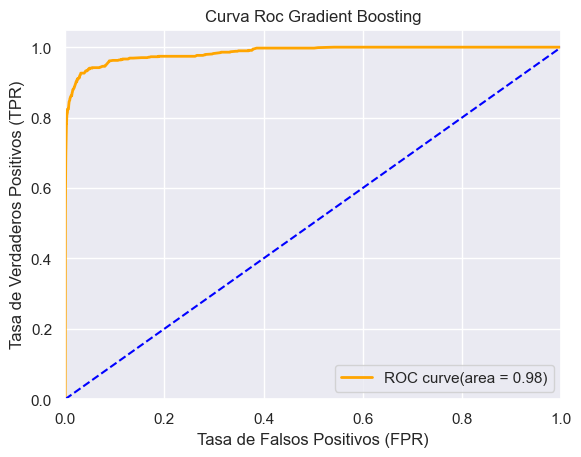

In [24]:
tfp, tvp, thr = roc_curve(y_test, y_probs_GB)
roc_auc = auc(tfp,tvp)

sns.set_theme(style="darkgrid")

sns.lineplot(x=tfp, y=tvp, color="orange", label=f"ROC curve(area = {roc_auc:.2f})", lw=2, linestyle="-")
sns.lineplot(x=[1,0], y=[1,0], color="blue", linestyle="--")
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva Roc Gradient Boosting")
plt.show()

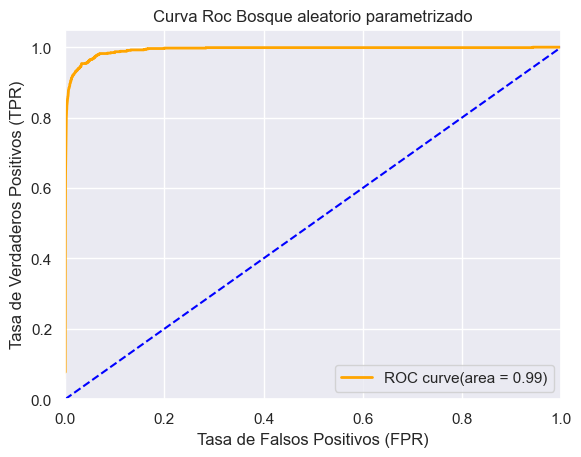

In [31]:
tfp, tvp, thr = roc_curve(y_test, y_probs_bh)
roc_auc = auc(tfp,tvp)

sns.set_theme(style="darkgrid")

sns.lineplot(x=tfp, y=tvp, color="orange", label=f"ROC curve(area = {roc_auc:.2f})", lw=2, linestyle="-")
sns.lineplot(x=[1,0], y=[1,0], color="blue", linestyle="--")
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva Roc Bosque aleatorio parametrizado")
plt.show()

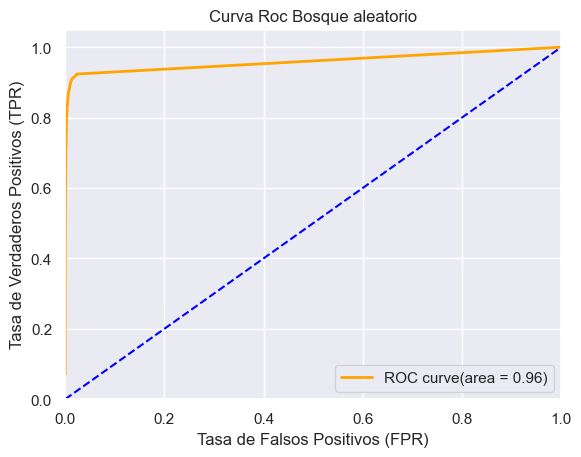

In [26]:
tfp, tvp, thr = roc_curve(y_test, y_probs_b)
roc_auc = auc(tfp,tvp)

sns.set_theme(style="darkgrid")

sns.lineplot(x=tfp, y=tvp, color="orange", label=f"ROC curve(area = {roc_auc:.2f})", lw=2, linestyle="-")
sns.lineplot(x=[1,0], y=[1,0], color="blue", linestyle="--")
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva Roc Bosque aleatorio")
plt.show()

In [27]:
recall_GB = recall_score(y_test, y_pred_GB)
f1_GB = f1_score(y_test, y_pred_GB)
precision_GB = precision_score(y_test, y_pred_GB)

recall_bh = recall_score(y_test, y_pred_bh)
f1_bh = f1_score(y_test, y_pred_bh)
precision_bh = precision_score(y_test, y_pred_bh)

recall_b = recall_score(y_test, y_pred_b)
f1_b= f1_score(y_test, y_pred_b)
precision_b = precision_score(y_test, y_pred_b)


In [28]:
print("Comparación de recall")
print("Gradient Boosting: ", round(recall_GB,3))
print("Random Forest: ", round(recall_b,3))
print("Random Forest Hyper: ", round(recall_bh,3))

Comparación de recall
Gradient Boosting:  0.647
Random Forest:  0.665
Random Forest Hyper:  0.624


In [29]:
print("Comparación de precision")
print("Gradient Boosting: ", precision_GB)
print("Random Forest: ", precision_b)
print("Random Forest Hyper: ", precision_bh)

Comparación de precision
Gradient Boosting:  0.8130081300813008
Random Forest:  0.7968992248062016
Random Forest Hyper:  0.8684684684684685


In [30]:
print("Comparación de f1")
print("Gradient Boosting: ", f1_GB)
print("Random Forest: ", f1_b)
print("Random Forest Hyper: ", f1_bh)

Comparación de f1
Gradient Boosting:  0.7204610951008645
Random Forest:  0.7249647390691114
Random Forest Hyper:  0.7259036144578314


In [28]:
y_probs_GB = model.predict_proba(x_test)[:,1]
precision_GB, recall_GB, thresholds_GB = precision_recall_curve(y_test,y_probs_GB)

y_probs_bh = bh.predict_proba(x_test)[:,1]
precision_bh, recall_bh, thresholds_bh = precision_recall_curve(y_test,y_probs_bh)

y_probs_b = b.predict_proba(x_test)[:,1]
precision_b, recall_b, thresholds_b = precision_recall_curve(y_test,y_probs_b)

In [120]:
ap_GB = average_precision_score(y_test, y_pred_GB)
ap_bh = average_precision_score(y_test, y_pred_bh)
ap_b = average_precision_score(y_test, y_pred_b)

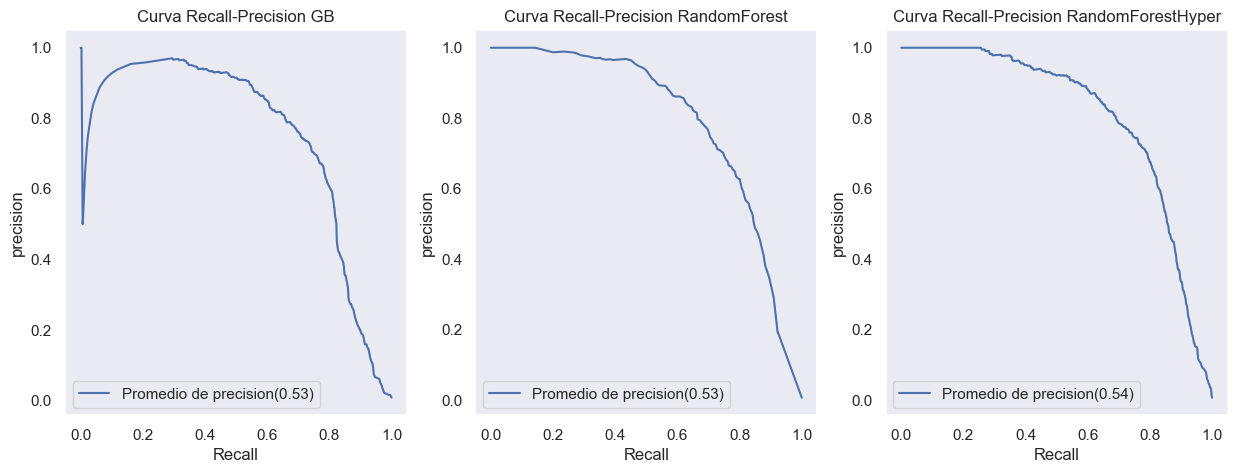

In [129]:
sns.set_theme(style="dark")

sub,ax = plt.subplots(1,3, figsize=(15,5))

sns.lineplot(x=recall_GB, y=precision_GB, label=f"Promedio de precision({round(ap_GB,2)})", ax=ax[0])
ax[0].set_title("Curva Recall-Precision GB")
ax[0].set_xlabel("Recall")
ax[0].set_ylabel("precision")

sns.lineplot(x=recall_b, y=precision_b, label=f"Promedio de precision({round(ap_b,2)})", ax=ax[1])
ax[1].set_title("Curva Recall-Precision RandomForest")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("precision")

sns.lineplot(x=recall_bh, y=precision_bh, label=f"Promedio de precision({round(ap_bh,2)})", ax=ax[2])
ax[2].set_title("Curva Recall-Precision RandomForestHyper")
ax[2].set_xlabel("Recall")
ax[2].set_ylabel("precision")
plt.show()

In [14]:
cm_GB = confusion_matrix(y_test, y_pred_GB)
disp_GB = ConfusionMatrixDisplay(confusion_matrix=cm_GB, display_labels=model.classes_)

cm_b = confusion_matrix(y_test, y_pred_b)
disp_b = ConfusionMatrixDisplay(confusion_matrix=cm_b, display_labels=b.classes_)

cm_bh = confusion_matrix(y_test, y_pred_bh)
disp_bh = ConfusionMatrixDisplay(confusion_matrix=cm_bh, display_labels=bh.classes_)


Text(0.5, 1.0, 'Matriz de confusión para RandomForest')

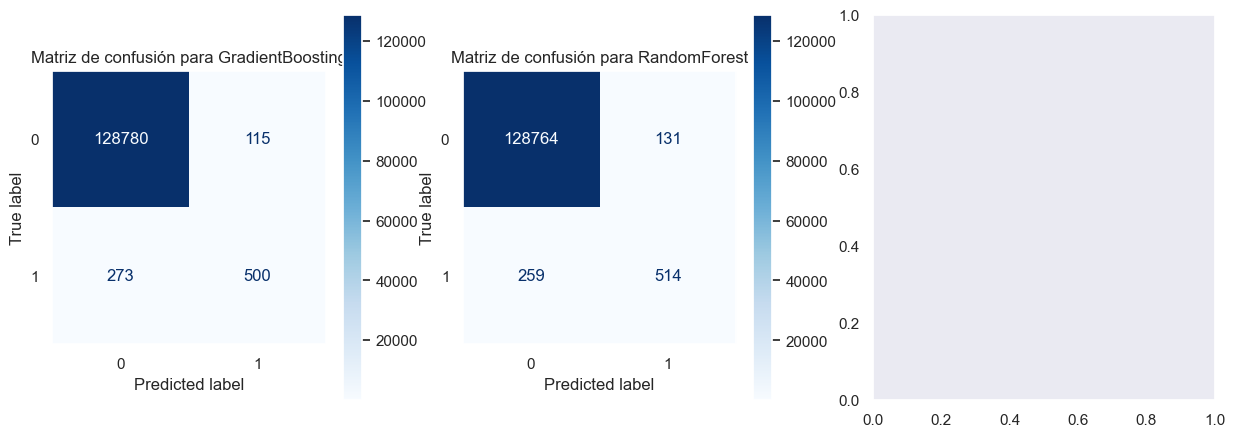

In [16]:
sns.set_theme(style="dark")

sub,ax = plt.subplots(1,3, figsize=(15,5))

disp_GB.plot(cmap="Blues",ax=ax[0])
ax[0].set_title("Matriz de confusión para GradientBoosting")

disp_b.plot(cmap="Blues",ax=ax[1])
ax[1].set_title("Matriz de confusión para RandomForest")

#disp_bh.plot(cmap="Blues",ax=ax[2])
#ax[2].set_title("Matriz de confusión para RandomForestHyper")
#plt.show()

In [49]:
for p,r,t in zip(precision_bh, recall_bh, thresholds_bh):
    if (r >= 0.82) & (p >=0.60):
        print(f"Umbral optimo RandomForestHyper:{t}, Recall:{r}, Precision:{p}")
        break

Umbral optimo RandomForestHyper:0.11730232425863889, Recall:0.8292367399741267, Precision:0.600187265917603


In [48]:
for p,r,t in zip(precision_b, recall_b, thresholds_b):
    if (r >= 0.80) & (p >=0.60):
        print(f"Umbral optimo RandomForest:{t}, Recall:{r}, Precision:{p}")
        break

Umbral optimo RandomForest:0.18, Recall:0.8072445019404916, Precision:0.6


In [47]:
for p,r,t in zip(precision_GB, recall_GB, thresholds_GB):
    if (r >= 0.80) & (p >=0.60):
        print(f"Umbral optimo GradientBoosting:{t}, Recall:{r}, Precision:{p}")
        break

Umbral optimo GradientBoosting:0.1040395603877239, Recall:0.8046571798188874, Precision:0.6003861003861004


## Exportando modelos

In [21]:
dump(bosque, "RandomForestClassifier.joblib", compress=9) # Exportando bosque aleatorio

['RandomForestClassifier.joblib']

In [22]:
dump(bosque_h, "RandomForestClassifierHyper.joblib", compress=9) # Exportando bosque aleatorio con hiperparametros

['RandomForestClassifierHyper.joblib']

In [23]:
dump(GB, "GBClassifier.joblib", compress=9) # Exportando boosting model

['GBClassifier.joblib']

## Guardando data

In [2]:
d = data.join(Y)
d.to_csv("FeaturedData.csv")

NameError: name 'data' is not defined

## Bosque Aleatorio Scratch

In [ ]:
class Nodo:
    def __init__(self, derecha=None, izquierda=None, columna=None, threshold=None, data=None):
        self.derecha = derecha
        self.izquierda = izquierda
        self.columna = columna
        self.threshold = threshold
        self.data = data

    def es_hoja(self):
        y = self.data.columns[-1]
        if (self.data.shape[0] <2) or (len(self.data[y].unique()) == 1):
            return True
        else:
            return False

In [ ]:
class ArbolClasificador:
    def __init__(self, raiz=None, ):
        self.raiz = raiz

    def entrenar(self, x, y):
        df = pd.concat([x,y], axis=1)
        nodo = Nodo(data=df)

        if nodo.es_hoja():
            return self.raiz
        
        mejor_columna, mejor_thr = self.mejor_division(nodo)

        der = nodo.data[nodo.data[mejor_columna] > mejor_thr]
        x_der = der.iloc[:,:-1]
        y_der = der.iloc[:,-1]
        
        izq = nodo.data[nodo.data[mejor_columna] <= mejor_thr]
        x_izq = izq.iloc[:,:-1]
        y_izq = izq.iloc[:,-1]
        
        if not self.raiz:
            nodo.columna = mejor_columna
            nodo.threshold = mejor_threshold
            self.raiz = nodo
            self.raiz.izquierda = Nodo(data=izq)
            self.raiz.derecha = Nodo(data=der)

            self.raiz.izquierda.izquierda = self.entrenar(x_izq, y_izq)
            self.raiz.derecha.derecha = self.entrenar(x_der, y_der)
        else:
            nodo.columna = mejor_columna
            nodo.threshold = mejor_threshold
            nodo.izquierda = Nodo(data=izq)
            nodo.derecha = Nodo(data=der)

            nodo.izquierda.izquierda = self.entrenar(x_izq, y_izq)
            nodo.derecha.derecha = self.entrenar(x_der, y_der)
       
    def mejor_division(self, nodo: Nodo):
        mejor_gini = 1
        y_nombre = nodo.data.columns[-1]
        y = nodo.data[y_nombre].unique() 
        n = nodo.data.shape[0]
        threshold, columna= None, None
        
        for col in nodo.data.columns[:-1]:
            for thr in nodo.data[col].unique():
                izq = nodo.data[nodo.data[col] <= thr]
                der = nodo.data[nodo.data[col] > thr]
                
                izq_ig = self.impuridad_gini(izq, col, thr, y, y_nombre, n)        
                der_ig = self.impuridad_gini(der, col, thr, y, y_nombre, n)
                gini_split = izq_ig + der_ig
                
                if gini_split < mejor_gini:
                    mejor_gini = gini_split
                    threshold = thr
                    columna = col

        return columna, threshold
    
    def impuridad_gini(self, subdivision, col, thr, objetivo, y_nombre, n):
        
        total = subdivision.shape[0]
        thr_0 = subdivision[subdivision[y_nombre] == objetivo[0]].count()
        thr_1 = subdivision[subdivision[y_nombre] == objetivo[1]].count()
        gini_thr = 1-(((thr_0/total)**2)+((thr_1/total)**2))
        gini_pesado = ((total*gini_thr)/n)
            
        return gini_pesado

In [ ]:
test_y = y_train[y_train == 1].head(4) 

In [ ]:
test_y

In [ ]:
test_x = x_train.iloc[[897129,945394,24023,568584]]

In [ ]:
b = ArbolClasificador()

In [ ]:
b.entrenar(x_test,y_test)

In [ ]:
import sklearn
dir(sklearn.metrics)

In [ ]:
print(GB)
print(bosque)
print(bosque_h)